# 🟠 Tarefa 5

* Disciplina: Física com Python 1 (2026.2) — CBPF
* Autor: Luiz Guilherme Ataliba dos Reis
* Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

> **Entrega:** colocar no GitHub.

In [19]:
import numpy as np
import ordpy
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme("notebook")
sns.set_style("darkgrid")

SEED = 42


In [ ]:
# Definições

# Mapa logístico: para a em [0,4] a órbita fica em [0,1]
def logistic(a=4, n=100_000, x0=0.4):
    x = np.zeros(n)                        # vetor que recebe a órbita
    x[0] = x0                              # condição inicial
    for i in range(n - 1):
        x[i + 1] = a * x[i] * (1 - x[i])   # itera o mapa a partir de x[i]
    return x


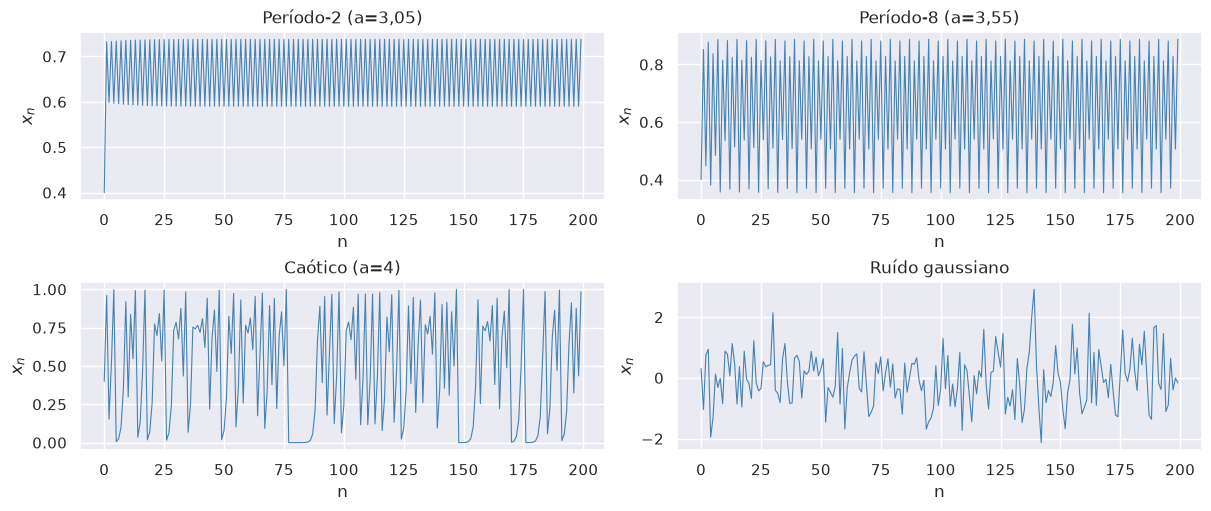

In [ ]:
# Dados

# Três séries do mapa logístico: períodos 2, 8 e o regime caótico
series = [logistic(a) for a in [3.05, 3.55, 4]]

# Ruído gaussiano branco: média 0 e desvio 1
rng = np.random.default_rng(SEED)
series.append(rng.normal(size=100_000))

rotulos = ["Período-2 (a=3,05)", "Período-8 (a=3,55)", "Caótico (a=4)", "Ruído gaussiano"]



# Visualização
fig, axs = plt.subplots(2, 2, figsize=(12, 5), constrained_layout=True)

for ax, serie, rotulo in zip(axs.ravel(), series, rotulos):
    ax.plot(serie[:200], lw=0.8, color="steelblue")
    ax.set(title=rotulo, xlabel="n", ylabel=r"$x_n$")


In [ ]:
# Entropia e complexidade

# complexity_entropy(série, dx=4) devolve o par (H, C) a partir da distribuição:
# H é a entropia de Shannon dessa distribuição dividida por ln(4!) = ln 24, então vai de 0 a 1
# C é a complexidade estatística de Shannon, normalizada para também ficar entre 0 e 1
HC = [ordpy.complexity_entropy(s, dx=4) for s in series]  # Calculando para as 4 séries


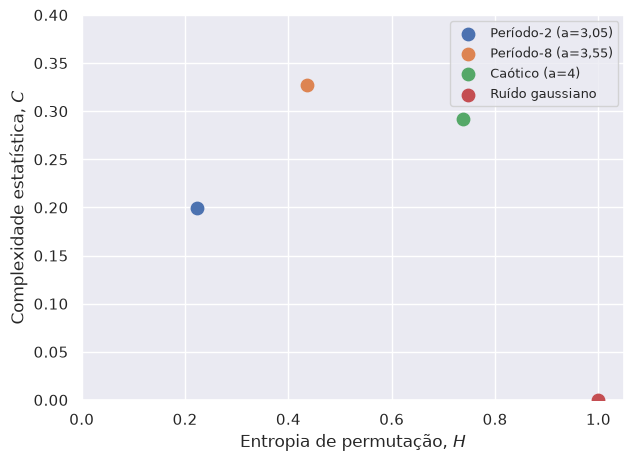

In [24]:
# Plotting

fig, ax = plt.subplots(figsize=(7, 5))

# O plano de entropia-complexidade: H no eixo x, C no eixo y, um ponto por série
for (h, c), rotulo in zip(HC, rotulos):
    ax.scatter(h, c, s=80, zorder=3, label=rotulo)

ax.set(
    xlabel="Entropia de permutação, $H$",
    ylabel="Complexidade estatística, $C$",
    xlim=(0, 1.05),
    ylim=(0, 0.4),
)
ax.legend(fontsize=9)


### 🔷 Interpretação

Observa-se que as séries periódicas apresentam valores menores de entropia, pois suas dinâmicas restringem o número de padrões ordinais visitados. Para a órbita de período 2, dois padrões dominam a distribuição. Já para a órbita de período 8, observamos quatro padrões aproximadamente equiprováveis.

No regime caótico, encontramos uma maior diversidade de padrões ordinais, resultando em uma entropia mais elevada. Entretanto, essa entropia não é máxima, pois, apesar de caótica, a dinâmica é determinística e apresenta restrições sobre os padrões temporais possíveis.

Para o ruído branco gaussiano, as observações são independentes e identicamente distribuídas, de modo que todos os padrões ordinais são teoricamente equiprováveis. Consequentemente, a entropia tende ao seu valor máximo, $H=1$, enquanto o desequilíbrio estatístico tende a zero, resultando em complexidade aproximadamente nula.

Além disso, observa-se que a complexidade não cresce monotonicamente com a entropia. A órbita de período 8 apresenta a maior complexidade entre as séries analisadas, enquanto a série de ruído possui a maior entropia e a menor complexidade.

Portanto, esses resultados mostram que entropia e complexidade são grandezas cuja análise conjunta permite identificar diferenças na organização temporal de séries periódicas, caóticas e aleatórias, sendo ainda possível realizar a classificação dessas (manual ou até sendo possível gerar um modelo classificador) para identificar os diferentes regimes que essas séries pertecem. 